# LightGBM M0 and M1 on IEEE-CIS
This notebook adds LightGBM to the M0 / M1 comparison in `05_ieee_m0_m2.ipynb`, so IEEE-CIS has the same four model families as Sparkov (LR, RF, CatBoost and LightGBM)

- **Same data and evaluation as notebook 05**: the loading code (Section 1) and the `evaluate` function (Section 2) are copied from notebook 05, with the same seed, so the LightGBM rows can go straight into the notebook 05 results table

- **Same LightGBM settings as Sparkov**: 300 trees, learning rate 0.05 and 31 leaves, the settings used for LightGBM in `05_sparkov_m0_m2.ipynb` => the LightGBM family is set up the same way on both datasets

- **M0**: no class weights. **M1**: the same model with `class_weight="balanced"`, so M0 vs M1 shows the effect of the class weights on their own

- **No tuning yet**: like the other families, LightGBM keeps common default settings for M0 and M1 and is only tuned after M2 (notebook 07)

- **Code columns check**: `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are categories in notebook 05. `card1` alone has about 12,000 values, and LightGBM can overfit categorical columns with many values, so we also try these six columns as plain numbers

Run notebooks 03 and 04 from this branch first, so `ieee_features.pkl` and `feature_lists.json` have the current features

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

pd.set_option("display.max_columns", 100)

SEED = 100   # same seed as notebook 05
PROCESSED_DIR = Path("../data/processed")

## 1. Load the Features
Same as Section 1 of notebook 05:
- Only the training and validation rows are kept, so the test rows never reach a model

- The model inputs are the columns in `ieee_feature_cols`

- Categorical columns are stored as pandas categories with `"missing"` as its own value, and the six code columns are turned into text categories. LightGBM uses the pandas category type to find the categorical columns, so no extra encoding is needed. The categories are set before the split, so training and validation rows share the same category codes

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

feature_cols = feature_lists["ieee_feature_cols"]
cat_cols = [c for c in feature_cols if c in feature_lists["ieee_categorical_cols"] or c in CODE_AS_CATEGORY]
num_cols = [c for c in feature_cols if c not in cat_cols]

# notebook 04 no longer builds the card1 + addr1 features, so rerun 04 if they are still in the list
old_cols = [c for c in feature_cols if "card1_addr1" in c]
if old_cols:
    raise RuntimeError(f"rerun notebook 04 first, these card1 + addr1 features are still in the feature list: {old_cols}")

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes, e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

train = features[features["ieee_split"] == "train"]
val = features[features["ieee_split"] == "validation"]
del features

X_train, y_train = train[feature_cols], train["isFraud"]
X_val, y_val = val[feature_cols], val["isFraud"]
val_day = (val["TransactionDT"] // 86400).to_numpy()

print("training rows:", len(train), "| fraud rate:", round(y_train.mean() * 100, 2), "%")
print("validation rows:", len(val), "| fraud rate:", round(y_val.mean() * 100, 2), "% | days:", len(np.unique(val_day)))
print("features:", len(feature_cols), "| numeric:", len(num_cols), "| categorical (with the 6 code columns):", len(cat_cols))

training rows: 377945 | fraud rate: 3.41 %
validation rows: 94487 | fraud rate: 3.92 % | days: 33
features: 575 | numeric: 528 | categorical (with the 6 code columns): 47


## 2. Evaluation Metrics
The `evaluate` function from notebook 05, so the scores are directly comparable:
- **PR-AUC** (main metric). Random ranking gets about the fraud rate, 0.039 on the validation rows

- **ROC-AUC**

- **Precision, recall and F1** at a threshold of 0.5 (no threshold chosen yet)

- **Precision@100 per day**: the share of fraud among each validation day's 100 highest scores, averaged over the days

- **Confusion matrix counts** at 0.5

In [3]:
val_scores = {}   # validation scores of every model
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]


def evaluate(name):
    scores = val_scores[name]
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


# show the scores of one or more models as a table
def show(*names):
    display(pd.DataFrame([evaluate(name) for name in names]).set_index("model").round(4))

## 3. LightGBM Settings
- **Settings**: 300 trees, learning rate 0.05, 31 leaves and no depth limit, the same as LightGBM on Sparkov. All other settings are LightGBM defaults

- **Categorical columns**: LightGBM finds them through the pandas category type. Missing numeric values are handled by LightGBM itself, so the numeric columns are used as they are

- **M1**: `class_weight="balanced"` weights each class by the inverse of its share of the training rows, the same rule as the other families in notebook 05 (a fraud transaction counts about 28 times as much as a non-fraud one)

- **Training time** is recorded for each model, because M2 retrains the model many times and the time per fit matters when choosing the model for M2 onwards

In [4]:
base_settings = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "objective": "binary",
    "random_state": SEED,
    "n_jobs": -1,
    "verbosity": -1,
}
class_weight_settings = {"class_weight": "balanced"}

train_time = {}   # seconds per model
fitted = {}       # fitted models, kept for feature importance


def fit_lightgbm(name, settings, X_fit, X_score):
    start = time.time()
    model = lgb.LGBMClassifier(**settings)
    model.fit(X_fit, y_train)
    train_time[name] = time.time() - start
    val_scores[name] = model.predict_proba(X_score)[:, 1]
    fitted[name] = model
    print(f"{name} trained in {train_time[name]:.0f}s")
    show(name)

## 4. M0: No Class Weights

In [5]:
fit_lightgbm("M0 LightGBM", base_settings, X_train, X_val)

M0 LightGBM trained in 22s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M0 LightGBM,0.5945,0.9128,0.8426,0.3917,0.5348,0.5985,1451,271,2253,90512


## 5. M1: Class Weights
Same features and settings as M0, plus `class_weight="balanced"`. Class weights push all scores up, so precision, recall and F1 at 0.5 change even when the ranking stays the same => compare M0 and M1 on PR-AUC first

In [6]:
fit_lightgbm("M1 LightGBM", base_settings | class_weight_settings, X_train, X_val)

# change from M0 to M1 (M1 - M0)
m0, m1 = evaluate("M0 LightGBM"), evaluate("M1 LightGBM")
print("change from M0 to M1 (M1 - M0):")
display(pd.DataFrame([{metric: m1[metric] - m0[metric] for metric in metric_cols}], index=["LightGBM"]).round(4))

M1 LightGBM trained in 21s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
M1 LightGBM,0.568,0.9073,0.3733,0.6506,0.4744,0.5661,2410,4046,1294,86737


change from M0 to M1 (M1 - M0):


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
LightGBM,-0.0266,-0.0055,-0.4693,0.2589,-0.0604,-0.0324


## 6. Code Columns as Numbers
The six code columns have many values (`card1` about 12,000). For a categorical column, LightGBM looks for the best way to split its values into two groups, and with this many values it can find splits that only fit the training rows. Here the six columns are given as plain numbers instead (missing values become NaN), and everything else stays the same. This is only a check of how LightGBM handles these columns: LR, RF and CatBoost in notebook 05 keep them as categories

In [7]:
def codes_as_numbers(X):
    X = X.copy()
    for col in CODE_AS_CATEGORY:
        X[col] = pd.to_numeric(X[col].astype(str), errors="coerce").astype("float32")   # "missing" becomes NaN
    return X


X_train_num, X_val_num = codes_as_numbers(X_train), codes_as_numbers(X_val)
print("categorical columns left:", sum(X_train_num[c].dtype == "category" for c in feature_cols))

fit_lightgbm("M0 LightGBM, codes as numbers", base_settings, X_train_num, X_val_num)
fit_lightgbm("M1 LightGBM, codes as numbers", base_settings | class_weight_settings, X_train_num, X_val_num)

categorical columns left: 41
M0 LightGBM, codes as numbers trained in 18s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
"M0 LightGBM, codes as numbers",0.5924,0.9201,0.8259,0.388,0.5279,0.58,1437,303,2267,90480


M1 LightGBM, codes as numbers trained in 18s


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
"M1 LightGBM, codes as numbers",0.5557,0.9065,0.2906,0.6998,0.4107,0.55,2592,6326,1112,84457


## 7. Results
### 7.1 LightGBM Runs

In [8]:
lgb_results = pd.DataFrame([evaluate(name) for name in val_scores]).set_index("model")
lgb_results["training time (s)"] = pd.Series(train_time)
display(lgb_results.round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,training time (s)
model,,,,,,,,,,,
M0 LightGBM,0.5945,0.9128,0.8426,0.3917,0.5348,0.5985,1451,271,2253,90512,22.1938
M1 LightGBM,0.5680,0.9073,0.3733,0.6506,0.4744,0.5661,2410,4046,1294,86737,20.8303
"M0 LightGBM, codes as numbers",0.5924,0.9201,0.8259,0.3880,0.5279,0.5800,1437,303,2267,90480,17.6287
"M1 LightGBM, codes as numbers",0.5557,0.9065,0.2906,0.6998,0.4107,0.5500,2592,6326,1112,84457,18.2423


### 7.2 Comparison with the Other Families
The LR, RF and CatBoost rows are copied from the results table of notebook 05 (same training and validation rows, same metrics). Training times are not compared across notebooks, because they depend on the machine each notebook ran on

In [9]:
notebook_05 = pd.DataFrame(
    [
        ["M0 LR", 0.5265, 0.8876, 0.7773, 0.3618, 0.4937, 0.5282],
        ["M0 RF", 0.5591, 0.9095, 0.8887, 0.2802, 0.4261, 0.5558],
        ["M0 CatBoost", 0.6255, 0.9259, 0.8098, 0.4495, 0.5781, 0.6121],
        ["M1 LR", 0.5041, 0.8878, 0.1718, 0.7719, 0.2811, 0.5100],
        ["M1 RF", 0.5561, 0.9163, 0.5332, 0.5375, 0.5354, 0.5558],
        ["M1 CatBoost", 0.5906, 0.9219, 0.3209, 0.7203, 0.4440, 0.5812],
    ],
    columns=["model"] + metric_cols,
).set_index("model")

lgb_rows = lgb_results.loc[["M0 LightGBM", "M1 LightGBM"], metric_cols]
comparison = pd.concat([notebook_05, lgb_rows])
comparison.insert(0, "stage", [name.split()[0] for name in comparison.index])
display(comparison.sort_values(["stage", "PR-AUC"], ascending=[True, False]).round(4))

,stage,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
model,,,,,,,
M0 CatBoost,M0,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121
M0 LightGBM,M0,0.5945,0.9128,0.8426,0.3917,0.5348,0.5985
M0 RF,M0,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558
M0 LR,M0,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282
M1 CatBoost,M1,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812
M1 LightGBM,M1,0.5680,0.9073,0.3733,0.6506,0.4744,0.5661
M1 RF,M1,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558
M1 LR,M1,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100


### 7.3 Feature Importance (M0 LightGBM)
Total gain of each feature, i.e. how much the splits on that feature improve the training loss. This only describes what the fitted model uses, not whether a feature generalises to later data

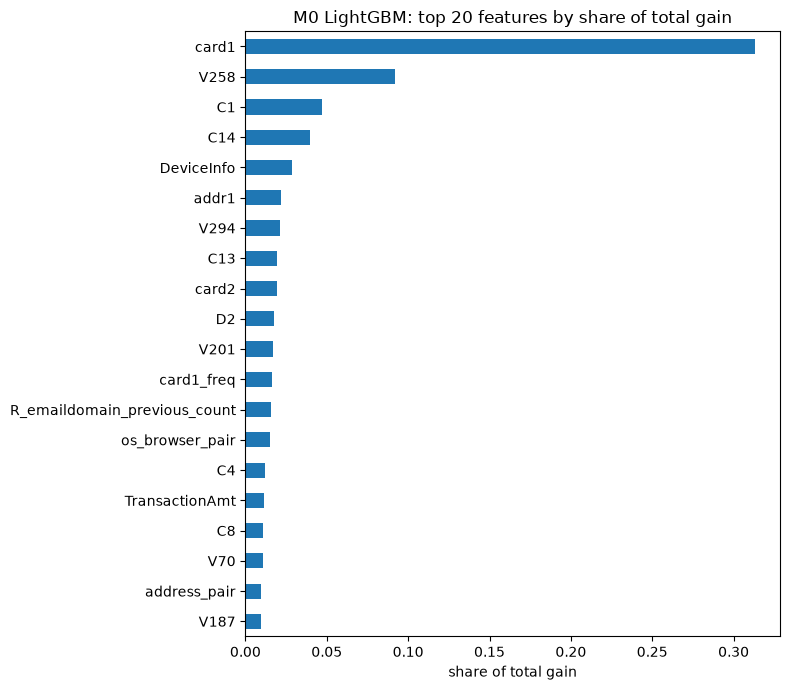

share of total gain from the six code columns: 0.355


In [10]:
importance = pd.Series(fitted["M0 LightGBM"].booster_.feature_importance(importance_type="gain"), index=feature_cols)
importance = (importance / importance.sum()).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
importance.head(20).iloc[::-1].plot.barh(ax=ax)
ax.set_title("M0 LightGBM: top 20 features by share of total gain")
ax.set_xlabel("share of total gain")
plt.tight_layout()
plt.show()

print("share of total gain from the six code columns:", round(importance[CODE_AS_CATEGORY].sum(), 3))

## 8. Takeaways
- **LightGBM is the second-best family at M0 and M1**: PR-AUC 0.595 (M0) and 0.568 (M1), behind CatBoost (0.626 / 0.591) and ahead of RF (0.559 / 0.556) and LR (0.527 / 0.504). Precision@100 per day is close to CatBoost (0.599 vs 0.612 at M0)

- **Class weights lower PR-AUC** (0.595 to 0.568), the same direction as every other family in notebook 05 => at the 0.5 threshold recall goes up (0.39 to 0.65) **BUT** precision drops (0.84 to 0.37), because the weights push all scores up instead of ranking the transactions better. So M2 for LightGBM is built on M0, like the other families (notebook 05c)

- **Code columns as numbers do not help**: PR-AUC 0.592 vs 0.595 (M0) and 0.556 vs 0.568 (M1) => we keep them as categories, the same as the other families. **BUT** these six columns give 35.5% of the total gain in M0, so the model leans heavily on `card1`-type codes (worth reading together with the card history check in notebook 05)

- **Training time**: about 20s per fit on all 377,945 training rows => fast enough to refit many times in M2

- **Settings note**: LightGBM uses 300 trees and learning rate 0.05 (the Sparkov settings), while CatBoost uses 500 trees and learning rate 0.1, so part of the 0.03 gap may come from the default settings. Both are tuned after M2 (notebook 07)